# RNN/LSTM classifier: accuracy experiments

This revision selects checkpoints and configurations by **bilateral accuracy**:
both leg states must be correct on the same sequence. Set `SELECTION_METRIC`
to `"macro_f1"` before training if equal performance across states is the goal.

Saved results in the supplied notebook (not results of this revision):

| Model | Test bilateral accuracy | Test average macro F1 |
| --- | ---: | ---: |
| Original unweighted LSTM | 54.23% | 0.5087 |
| Original fully class-weighted LSTM | 50.00% | 0.5317 |

The original left/right test accuracies were 57.96% and 80.85%. Left S1/S2
F1 scores were 0.27/0.14; right S1/S2/S3 were 0.29/0.40/0.20. These intermediate
states deserve attention. Full class weighting already improved macro F1 but
reduced the accuracy requested here.

Run this notebook in **Data Analysis 1 - Sara**, with the original CSVs in
`../Data`. Dependencies: TensorFlow, scikit-learn, pandas, NumPy, Matplotlib,
joblib, and a Jupyter/IPython environment. Outputs from the uploaded run have
been cleared so that old results cannot be mistaken for new measurements.

The revision adds label diagnostics, validation-metric checkpoint selection,
learning-rate reduction, and nine targeted training experiments. Trials 1–3
remain training data, trial 4 validation, and trial 5 the final test; each
candidate uses the same five-window sequences. No new training run has been
performed while preparing this file.

## Resolve the meaning of the five states

Your targets are **five relative tilt levels, not five activity labels**.
`normalize_score()` divides each recording's absolute thigh-tilt deviation
by that recording's 95th percentile. The same angle can therefore receive
different states in different recordings. A nearly stationary leg can also
have its small variations expanded across the state range. The scales are
computed from the complete recording, so these are retrospective proxy labels.

The diagnostics below show those scales and the fraction of samples agreeing
with each window's modal label. Inspect these before further architecture
tuning. To obtain consistent physical states, define thresholds from a
documented calibration or training reference and apply them unchanged to all
recordings; validate them against independent measurements. That is a separate
target-definition change and requires a new baseline. This revision retains
your current targets so its model experiments remain comparable.

## Model choices informed by the supplied paper

Azhiri et al., *Real-Time EMG Signal Classification via Recurrent Neural
Networks* (arXiv:2109.05674v1), use two-level **db1/Haar wavelet features**,
custom recurrent networks, and majority voting. Their best BRNN with repeated
same-window inputs reports 96.0% at 600 ms on the two-channel dataset and 93.3%
at 500 ms on the eight-channel dataset (Tables III–IV). These are finger-gesture
results, not a prediction of performance on the two-leg task here. Table IV
lists sequential RNN accuracy as 90.8% at 500 ms; the nearby prose differs.

Recommended next comparisons for this project:

1. **RBF-SVM and gradient boosting** on the existing 48 features: inexpensive
   nonlinear baselines for the current small training set. This ordering is a
   practical recommendation, not an experimental conclusion of the paper.
2. **Wavelet features plus a small bidirectional recurrent model**: the closest
   direction to the paper. A stock BiLSTM is an adaptation, not reproduction of
   the paper's custom five-unit BRNN. The added BiLSTM candidate below tests
   architecture only on the existing features; it does not yet add wavelets.
3. Add wavelet features from each window's **EMG samples** in the processed or
   raw files, not by transforming the 48 summary feature columns. The paper
   computes 19 statistics for each of three coefficient groups (57 per channel).
   Select/reduce features using training data only if the enlarged feature
   vector overfits.

The paper's 400-sample windows/200-sample hops correspond to 100/50 ms at its
4000-Hz sampling rate. Use your measured sampling rate when choosing window
durations. Its 500–600 ms signal/voting horizon is separate from compute time.
Test short causal voting against the unsmoothed predictions on validation
recordings: your tilt states change within a movement, so longer voting can
delay transitions and reduce intermediate-state accuracy.

The original right-leg accuracy already exceeds 80%, but left-leg and bilateral
accuracy do not. For an 80% bilateral requirement, select and report the
both-legs-correct metric explicitly. No architecture in this paper establishes
that target for these recordings or the current per-recording tilt labels.

[Paper](https://arxiv.org/abs/2109.05674)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import re
import unicodedata

from pathlib import Path

from sklearn.linear_model import RidgeClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

N_STATES = 5
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

In [2]:
DATA_DIR = Path("../Data")
RESULTS_DIR = Path("results/rnn_lstm_accuracy_tuning")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Data folder exists:", DATA_DIR.exists())
if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Run this notebook from Data Analysis 1 - Sara, or update DATA_DIR. "
        "The original *_features.csv and *_processed.csv files are required."
    )
print("Feature files:", len(list(DATA_DIR.glob("*_features.csv"))))
print("Processed files:", len(list(DATA_DIR.glob("*_processed.csv"))))

Data folder exists: True
Feature files: 26
Processed files: 26


In [3]:
def clean_name(name):
    name = unicodedata.normalize("NFKC", name)

    name = "".join(
        char for char in name
        if unicodedata.category(char) != "Cf"
    )

    return name.strip().lower()


def get_recording_key(filepath):

    name = clean_name(filepath.stem)

    name = re.sub(
        r"_(features|processed)$",
        "",
        name
    )

    if name.startswith("abduct"):
        movement = "abduction"

    elif name.startswith("elevate"):
        movement = "elevating"

    elif name.startswith("flex"):
        movement = "flexing"

    elif name.startswith("sitting"):
        movement = "sitting"

    elif name.startswith("standing"):
        movement = "standing"

    elif name.startswith("walking"):
        movement = "walking"

    else:
        return None

    match = re.search(r"z\s*(\d+)", name)

    if match:
        trial = int(match.group(1))

    elif movement == "standing":
        trial = 1

    else:
        return None

    return movement, trial


feature_files = {}
processed_files = {}

for filepath in DATA_DIR.glob("*_features.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in feature_files:
            raise ValueError(f"Duplicate feature file: {key}")
        feature_files[key] = filepath


for filepath in DATA_DIR.glob("*_processed.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in processed_files:
            raise ValueError(f"Duplicate processed file: {key}")
        processed_files[key] = filepath


common_keys = sorted(
    set(feature_files) & set(processed_files)
)

print("Matched recordings:", len(common_keys))

print("\nMissing processed recordings:")
print(sorted(set(feature_files) - set(processed_files)))

print("\nMissing feature recordings:")
print(sorted(set(processed_files) - set(feature_files)))

if not common_keys:
    raise ValueError("No matching recordings found.")

Matched recordings: 26

Missing processed recordings:
[]

Missing feature recordings:
[]


In [4]:
standing_key = ("standing", 1)

if standing_key not in processed_files:
    raise FileNotFoundError(
        "Standing processed file is missing."
    )


def accel_tilt_deg(df, side):

    x = pd.to_numeric(
        df[f"Thigh_{side}_Accel_X"],
        errors="coerce"
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Y"],
        errors="coerce"
    ).to_numpy(dtype=float)

    z = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Z"],
        errors="coerce"
    ).to_numpy(dtype=float)

    return np.degrees(
        np.arctan2(
            np.sqrt(x**2 + y**2),
            z
        )
    )


standing = pd.read_csv(
    processed_files[standing_key]
)

neutral_L = np.nanmedian(
    accel_tilt_deg(standing, "L")
)

neutral_R = np.nanmedian(
    accel_tilt_deg(standing, "R")
)

if not np.isfinite([neutral_L, neutral_R]).all():
    raise ValueError("Invalid standing reference.")

print("Left neutral:", neutral_L)
print("Right neutral:", neutral_R)

Left neutral: 101.62686114319813
Right neutral: 101.0616092669301


In [5]:
def normalize_score(values):

    values = np.array(
        values,
        dtype=float,
        copy=True
    )

    values[~np.isfinite(values)] = np.nan

    if np.all(np.isnan(values)):
        return np.full_like(values, np.nan)

    high = np.nanpercentile(values, 95)

    if not np.isfinite(high) or high <= 0:
        return np.full_like(values, np.nan)

    return np.clip(values / high, 0, 1)


def score_to_state(scores):

    scores = np.array(
        scores,
        dtype=float,
        copy=True
    )

    states = np.full(scores.shape, np.nan)

    valid = np.isfinite(scores)

    states[valid] = np.clip(
        np.floor(scores[valid] * N_STATES),
        0,
        N_STATES - 1
    )

    return states


def generate_states(processed):

    result = processed.copy()

    tilt_L = accel_tilt_deg(result, "L")
    tilt_R = accel_tilt_deg(result, "R")

    movement_L = np.abs(tilt_L - neutral_L)
    movement_R = np.abs(tilt_R - neutral_R)

    score_L = normalize_score(movement_L)
    score_R = normalize_score(movement_R)

    result["State_L"] = score_to_state(score_L)
    result["State_R"] = score_to_state(score_R)

    return result


print("State-generation functions ready.")

State-generation functions ready.


In [6]:
all_aligned = []
alignment_report = []
label_scale_rows = []

for key in common_keys:

    movement, trial = key

    features = pd.read_csv(feature_files[key])
    processed = pd.read_csv(processed_files[key])

    # Diagnostic only: these are the recording-specific label scales
    # already used by generate_states(), not model input features.
    scale_row = {"recording_id": f"{movement}_z{trial}",
                 "movement": movement, "trial": trial}
    for side, neutral in [("L", neutral_L), ("R", neutral_R)]:
        deviations = np.abs(accel_tilt_deg(processed, side) - neutral)
        finite = deviations[np.isfinite(deviations)]
        scale_row[f"tilt_p95_{side}_deg"] = (
            float(np.percentile(finite, 95)) if len(finite) else np.nan
        )
    label_scale_rows.append(scale_row)
    processed = generate_states(processed)

    processed["sample_index"] = pd.to_numeric(
        processed["sample_index"],
        errors="coerce"
    )

    processed = processed.dropna(
        subset=["sample_index"]
    ).sort_values("sample_index")

    sample_indices = processed["sample_index"].to_numpy()

    rows = []

    for _, row in features.iterrows():

        start = pd.to_numeric(
            row["start_sample_index"],
            errors="coerce"
        )

        end = pd.to_numeric(
            row["end_sample_index"],
            errors="coerce"
        )

        if not np.isfinite(start) or not np.isfinite(end):
            continue

        mask = (
            (sample_indices >= start)
            & (sample_indices <= end)
        )

        window = processed.loc[mask].dropna(
            subset=["State_L", "State_R"]
        )

        if window.empty:
            continue

        output = row.to_dict()

        output["State_L"] = int(
            window["State_L"].mode().iloc[0]
        )

        output["State_R"] = int(
            window["State_R"].mode().iloc[0]
        )

        # A low purity means that a feature window contains several states.
        output["label_purity_L"] = float(
            (window["State_L"] == output["State_L"]).mean()
        )
        output["label_purity_R"] = float(
            (window["State_R"] == output["State_R"]).mean()
        )

        output["movement"] = movement
        output["trial"] = trial
        output["recording_id"] = f"{movement}_z{trial}"

        rows.append(output)

    alignment_report.append({
        "Recording": f"{movement}_z{trial}",
        "Original Windows": len(features),
        "Aligned Windows": len(rows)
    })

    if rows:
        all_aligned.append(pd.DataFrame(rows))


if not all_aligned:
    raise ValueError("No aligned windows created.")

data = pd.concat(
    all_aligned,
    ignore_index=True
)

print("Aligned dataset:", data.shape)
print("Recordings:", data["recording_id"].nunique())

display(pd.DataFrame(alignment_report))

Aligned dataset: (2281, 60)
Recordings: 26


,Recording,Original Windows,Aligned Windows
0,abduction_z1,70,70
1,abduction_z2,56,56
2,abduction_z3,66,66
3,abduction_z4,72,72
4,abduction_z5,78,78
5,elevating_z1,120,120
6,elevating_z2,122,122
7,elevating_z3,99,99
8,elevating_z4,84,84
9,elevating_z5,95,95


In [7]:
label_scale_report = pd.DataFrame(label_scale_rows)
print("95th-percentile tilt deviations used to create each recording's labels:")
display(label_scale_report)

print("Range of label scales across trials of each movement:")
display(label_scale_report.groupby("movement")[["tilt_p95_L_deg", "tilt_p95_R_deg"]]
        .agg(["min", "max"]))

print("Window label purity (1 means every valid sample has the modal state):")
display(data.groupby("movement")[["label_purity_L", "label_purity_R"]].mean())
for side in ["L", "R"]:
    print(f"{side}: {(data[f'label_purity_{side}'] < 0.6).mean():.1%} of windows "
          "have less than 60% agreement with their assigned label")
label_scale_report.to_csv(RESULTS_DIR / "label_scales.csv", index=False)

95th-percentile tilt deviations used to create each recording's labels:


,recording_id,movement,trial,tilt_p95_L_deg,tilt_p95_R_deg
0,abduction_z1,abduction,1,24.952018,39.809184
1,abduction_z2,abduction,2,39.924303,52.281642
2,abduction_z3,abduction,3,32.678711,47.352114
3,abduction_z4,abduction,4,36.458417,47.852595
4,abduction_z5,abduction,5,35.460928,42.300355
5,elevating_z1,elevating,1,25.944918,67.603356
6,elevating_z2,elevating,2,21.443851,64.896331
7,elevating_z3,elevating,3,22.210972,60.065642
8,elevating_z4,elevating,4,23.375538,67.933051
9,elevating_z5,elevating,5,19.981453,67.315477


Range of label scales across trials of each movement:


tilt_p95_L_deg            tilt_p95_R_deg           
                     min        max            min        max
movement                                                     
abduction      24.952018  39.924303      39.809184  52.281642
elevating      19.981453  25.944918      60.065642  67.933051
flexing        16.436863  33.694963      37.930583  45.256308
sitting        58.054319  62.784770      65.058450  69.966084
standing        0.918255   0.918255       0.910370   0.910370
walking        12.650002  17.229471      24.212993  25.571234

Window label purity (1 means every valid sample has the modal state):


,label_purity_L,label_purity_R
movement,,
abduction,0.823165,0.930205
elevating,0.796707,0.958562
flexing,0.804767,0.945528
sitting,0.909134,0.914287
standing,0.725509,0.634321
walking,0.596028,0.736591


L: 24.6% of windows have less than 60% agreement with their assigned label
R: 11.8% of windows have less than 60% agreement with their assigned label


In [8]:
FEATURE_SUFFIXES = (
    "_rms",
    "_mav",
    "_iemg",
    "_waveform_length",
    "_zero_crossings",
    "_slope_sign_changes"
)

feature_columns = [
    col for col in data.columns
    if col.endswith(FEATURE_SUFFIXES)
]

print("Number of features:", len(feature_columns))

if len(feature_columns) != 48:
    raise ValueError(
        f"Expected 48 features, found {len(feature_columns)}"
    )

data[feature_columns] = data[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

data[feature_columns] = data[feature_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

print("EMG features ready.")

Number of features: 48
EMG features ready.


In [9]:
# Standing is used for the neutral reference
model_data = data[
    data["movement"] != "standing"
].copy()

TRAIN_TRIALS = [1, 2, 3]
VAL_TRIALS = [4]
TEST_TRIALS = [5]

train_mask = model_data["trial"].isin(TRAIN_TRIALS)
val_mask = model_data["trial"].isin(VAL_TRIALS)
test_mask = model_data["trial"].isin(TEST_TRIALS)

X_train = model_data.loc[train_mask, feature_columns].copy()
X_val = model_data.loc[val_mask, feature_columns].copy()
X_test = model_data.loc[test_mask, feature_columns].copy()

y_train = model_data.loc[
    train_mask, ["State_L", "State_R"]
].copy()

y_val = model_data.loc[
    val_mask, ["State_L", "State_R"]
].copy()

y_test = model_data.loc[
    test_mask, ["State_L", "State_R"]
].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1289, 48)
Validation: (408, 48)
Testing: (422, 48)


In [10]:
train_ids = set(model_data.loc[train_mask, "recording_id"])
val_ids = set(model_data.loc[val_mask, "recording_id"])
test_ids = set(model_data.loc[test_mask, "recording_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

assert y_train.notna().all().all()
assert y_val.notna().all().all()
assert y_test.notna().all().all()

print("Training recordings:", len(train_ids))
print("Validation recordings:", len(val_ids))
print("Testing recordings:", len(test_ids))

print("\nTraining state distribution:")

print("Left:")
print(y_train["State_L"].value_counts().sort_index())

print("\nRight:")
print(y_train["State_R"].value_counts().sort_index())

print("\nData verification completed.")

Training recordings: 15
Validation recordings: 5
Testing recordings: 5

Training state distribution:
Left:
State_L
0    395
1    231
2    238
3    182
4    243
Name: count, dtype: int64

Right:
State_R
0    774
1     85
2     56
3    103
4    271
Name: count, dtype: int64

Data verification completed.


In [11]:
import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    LSTM, Bidirectional, Dense, Dropout, Cropping1D, Flatten, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(RANDOM_STATE)

# Pick the objective BEFORE training and inspecting the held-out trial.
# "bilateral_accuracy": both legs must be correct on the same sequence.
# "macro_f1": each state receives equal importance within each leg.
SELECTION_METRIC = "bilateral_accuracy"
assert SELECTION_METRIC in {"bilateral_accuracy", "macro_f1"}
MAX_EPOCHS = 100
BATCH_SIZE = 32

In [12]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    imputer.fit_transform(X_train)
)

X_val_scaled = scaler.transform(
    imputer.transform(X_val)
)

X_test_scaled = scaler.transform(
    imputer.transform(X_test)
)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (1289, 48)
Validation: (408, 48)
Testing: (422, 48)


In [13]:
SEQUENCE_LENGTH = 5

def create_sequences(X, y, recording_ids, times):

    X_seq = []
    y_seq = []
    seq_ids = []
    seq_times = []

    for recording in np.unique(recording_ids):

        indices = np.where(recording_ids == recording)[0]

        # Sort the recording's windows by time
        indices = indices[np.argsort(times[indices])]

        for i in range(SEQUENCE_LENGTH - 1, len(indices)):

            selected = indices[
                i - SEQUENCE_LENGTH + 1 : i + 1
            ]

            X_seq.append(X[selected])

            # Label corresponds to the final window
            y_seq.append(y[selected[-1]])

            seq_ids.append(recording)
            seq_times.append(times[selected[-1]])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.int32),
        np.asarray(seq_ids),
        np.asarray(seq_times)
    )

In [14]:
def prepare_sequences(X_scaled, y, mask):

    recording_ids = model_data.loc[
        mask, "recording_id"
    ].to_numpy()

    times = model_data.loc[
        mask, "end_time_s"
    ].to_numpy()

    return create_sequences(
        X_scaled,
        y.to_numpy(),
        recording_ids,
        times
    )


X_train_seq, y_train_seq, train_ids, train_times = prepare_sequences(
    X_train_scaled, y_train, train_mask
)

X_val_seq, y_val_seq, val_ids, val_times = prepare_sequences(
    X_val_scaled, y_val, val_mask
)

X_test_seq, y_test_seq, test_ids, test_times = prepare_sequences(
    X_test_scaled, y_test, test_mask
)

print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)

assert len(X_train_seq) > 0
assert len(X_val_seq) > 0
assert len(X_test_seq) > 0

for split_name, X_seq, y_seq in [
    ("train", X_train_seq, y_train_seq),
    ("validation", X_val_seq, y_val_seq),
    ("test", X_test_seq, y_test_seq),
]:
    assert X_seq.ndim == 3 and X_seq.shape[1:] == (SEQUENCE_LENGTH, 48)
    assert np.isfinite(X_seq).all(), f"Non-finite inputs in {split_name}"
    assert y_seq.shape == (len(X_seq), 2)
    assert ((y_seq >= 0) & (y_seq < N_STATES)).all()

Training sequences: (1229, 5, 48)
Validation sequences: (388, 5, 48)
Testing sequences: (402, 5, 48)


In [15]:
def build_rnn(units=32, dropout=0.3, learning_rate=1e-3,
              left_loss_weight=1.0, last_window_skip=False,
              architecture="lstm"):
    inputs = Input(shape=(SEQUENCE_LENGTH, len(feature_columns)))
    if architecture == "lstm":
        x = LSTM(units)(inputs)
    elif architecture == "bilstm":
        # A practical paper-inspired adaptation, not the paper's custom BRNN.
        # All five windows end at or before the prediction timestamp.
        x = Bidirectional(LSTM(units))(inputs)
    else:
        raise ValueError(f"Unknown recurrent architecture: {architecture}")
    x = Dropout(dropout)(x)

    if last_window_skip:
        # The target is the final feature window's state. Let the head use
        # that window directly as well as the LSTM's temporal representation.
        last = Cropping1D(cropping=(SEQUENCE_LENGTH - 1, 0))(inputs)
        last = Flatten()(last)
        x = Concatenate()([x, last])

    x = Dense(16, activation="relu")(x)
    left_output = Dense(N_STATES, activation="softmax", name="left_state")(x)
    right_output = Dense(N_STATES, activation="softmax", name="right_state")(x)
    model = Model(inputs=inputs, outputs=[left_output, right_output])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss=["sparse_categorical_crossentropy",
              "sparse_categorical_crossentropy"],
        loss_weights=[left_loss_weight, 1.0],
        metrics={"left_state": ["accuracy"], "right_state": ["accuracy"]},
    )
    return model

build_rnn().summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5, 48)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     10,368 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        528 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ left_state (Dense)  │ (None, 5)         │         85 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ right_state (Dense) │ (None, 5)         │         85 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,066 (43.23 KB)

 Trainable params: 11,066 (43.23 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
def calculate_average_macro_f1(y_true, pred_L, pred_R):
    scores = [
        f1_score(y_true[:, side], pred, labels=range(N_STATES),
                 average="macro", zero_division=0)
        for side, pred in [(0, pred_L), (1, pred_R)]
    ]
    return float(np.mean(scores))


def score_candidate(model, X, y):
    prob_L, prob_R = model.predict(X, verbose=0)
    pred_L, pred_R = np.argmax(prob_L, axis=1), np.argmax(prob_R, axis=1)
    return {
        "macro_f1": calculate_average_macro_f1(y, pred_L, pred_R),
        "bilateral_accuracy": float(np.mean(
            (pred_L == y[:, 0]) & (pred_R == y[:, 1])
        )),
        "left_accuracy": float(np.mean(pred_L == y[:, 0])),
        "right_accuracy": float(np.mean(pred_R == y[:, 1])),
    }


def balanced_sample_weights(y, power=0.0):
    # power=0: unweighted; 0.5: milder weighting; 1: fully balanced.
    # Compute weights from TRAINING SEQUENCES only, then keep mean weight 1.
    y = np.asarray(y, dtype=np.int32)
    if y.ndim != 1 or not len(y):
        raise ValueError("Expected a nonempty one-dimensional label array")
    if power < 0 or not ((y >= 0) & (y < N_STATES)).all():
        raise ValueError("Invalid weight power or state labels")
    counts = np.bincount(y, minlength=N_STATES)
    present = counts > 0
    lookup = np.ones(N_STATES, dtype=np.float64)
    lookup[present] = len(y) / (present.sum() * counts[present])
    weights = lookup[y] ** power
    return (weights / weights.mean()).astype(np.float32)


class ValidationScores(tf.keras.callbacks.Callback):
    """Expose full-validation metrics before EarlyStopping reads the logs."""
    def __init__(self, X_validation, y_validation):
        super().__init__()
        self.X_validation = X_validation
        self.y_validation = y_validation

    def on_epoch_end(self, epoch, logs=None):
        scores = score_candidate(self.model, self.X_validation, self.y_validation)
        if logs is not None:
            logs.update({f"val_{name}": score for name, score in scores.items()})

## Select using validation data

The first candidate retains the original architecture and learning rate, but
uses the revised checkpoint rule and learning-rate schedule. It is a reference
within this search, not an exact reproduction of the saved original run.
Each additional candidate changes one factor. The mild and full weight
experiments are compared against unweighted training on the chosen metric.

The custom callback computes bilateral accuracy and average macro F1 over the
whole validation set at every epoch. It runs before `EarlyStopping`, which
restores the checkpoint with the best selected metric. Learning-rate reduction
still monitors validation loss. The candidate search never scores trial 5.

Nine candidates are an initial screen. Check stability across independent
recordings and predeclared seeds using training/validation trials before making
claims of improvement. Once trial 5 has informed further design changes, use
new recordings as the final independent test.

In [17]:
# A small, targeted search: identical splits, five-window context, and
# validation examples for every candidate. No model selection uses trial 5.
base_config = dict(units=32, dropout=0.3, learning_rate=1e-3,
                   weight_power=0.0, left_loss_weight=1.0,
                   last_window_skip=False, architecture="lstm")
configurations = [
    {**base_config, "name": "reference_architecture"},
    {**base_config, "name": "less_dropout", "dropout": 0.15},
    {**base_config, "name": "lower_learning_rate", "learning_rate": 3e-4},
    {**base_config, "name": "more_units", "units": 64, "dropout": 0.2},
    {**base_config, "name": "last_window_skip", "last_window_skip": True},
    {**base_config, "name": "mild_class_weights", "weight_power": 0.5},
    {**base_config, "name": "full_class_weights", "weight_power": 1.0},
    {**base_config, "name": "left_loss_emphasis", "left_loss_weight": 1.5},
    {**base_config, "name": "paper_inspired_bilstm", "architecture": "bilstm"},
]

tuning_results = []
best_score = -np.inf
best_model = best_config = best_history = None
monitor = f"val_{SELECTION_METRIC}"

for config in configurations:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = build_rnn(**{
        key: value for key, value in config.items()
        if key not in {"name", "weight_power"}
    })
    early_stopping = EarlyStopping(
        monitor=monitor, mode="max", patience=15,
        restore_best_weights=True,
    )
    callbacks = [
        # Ordering matters: add custom scores before other callbacks read them.
        ValidationScores(X_val_seq, y_val_seq),
        ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5,
                          patience=4, min_lr=1e-5),
        early_stopping,
    ]
    history = model.fit(
        X_train_seq,
        [y_train_seq[:, 0], y_train_seq[:, 1]],
        sample_weight=[
            balanced_sample_weights(y_train_seq[:, side], config["weight_power"])
            for side in range(2)
        ],
        validation_data=(X_val_seq, [y_val_seq[:, 0], y_val_seq[:, 1]]),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=callbacks, verbose=0,
    )
    # EarlyStopping has restored the checkpoint with the best chosen metric.
    scores = score_candidate(model, X_val_seq, y_val_seq)
    chosen_epoch = int(np.argmax(history.history[monitor])) + 1
    row = {**config, "best_epoch": chosen_epoch,
           "epochs_run": len(history.history["loss"]), **scores}
    tuning_results.append(row)
    print(f"{config['name']}: validation bilateral={scores['bilateral_accuracy']:.4f}, "
          f"macro F1={scores['macro_f1']:.4f}, selected epoch={chosen_epoch}")
    if scores[SELECTION_METRIC] > best_score:
        best_score = scores[SELECTION_METRIC]
        best_model, best_config, best_history = model, config.copy(), history

rnn_tuning = pd.DataFrame(tuning_results).sort_values(
    SELECTION_METRIC, ascending=False, kind="stable"
)
display(rnn_tuning)
rnn_tuning.to_csv(RESULTS_DIR / "validation_tuning.csv", index=False)
rnn_model = best_model
print("Selection objective:", SELECTION_METRIC)
print("Selected configuration:", best_config)
print("Now evaluate the selected model on held-out trial 5 below.")

reference_architecture: validation bilateral=0.5515, macro F1=0.5105, selected epoch=25
less_dropout: validation bilateral=0.5490, macro F1=0.5335, selected epoch=27
lower_learning_rate: validation bilateral=0.5180, macro F1=0.4805, selected epoch=24
more_units: validation bilateral=0.5902, macro F1=0.5833, selected epoch=43
last_window_skip: validation bilateral=0.5979, macro F1=0.5625, selected epoch=28
mild_class_weights: validation bilateral=0.5361, macro F1=0.5744, selected epoch=21
full_class_weights: validation bilateral=0.5258, macro F1=0.6085, selected epoch=46
left_loss_emphasis: validation bilateral=0.5387, macro F1=0.5194, selected epoch=13
paper_inspired_bilstm: validation bilateral=0.6057, macro F1=0.6089, selected epoch=22


,units,dropout,learning_rate,weight_power,left_loss_weight,last_window_skip,architecture,name,best_epoch,epochs_run,macro_f1,bilateral_accuracy,left_accuracy,right_accuracy
8,32,0.30,0.0010,0.0,1.0,False,bilstm,paper_inspired_bilstm,22,37,0.608896,0.605670,0.685567,0.840206
4,32,0.30,0.0010,0.0,1.0,True,lstm,last_window_skip,28,43,0.562544,0.597938,0.667526,0.809278
3,64,0.20,0.0010,0.0,1.0,False,lstm,more_units,43,58,0.583343,0.590206,0.662371,0.822165
0,32,0.30,0.0010,0.0,1.0,False,lstm,reference_architecture,25,40,0.510504,0.551546,0.631443,0.780928
1,32,0.15,0.0010,0.0,1.0,False,lstm,less_dropout,27,42,0.533457,0.548969,0.641753,0.793814
7,32,0.30,0.0010,0.0,1.5,False,lstm,left_loss_emphasis,13,28,0.519417,0.538660,0.618557,0.811856
5,32,0.30,0.0010,0.5,1.0,False,lstm,mild_class_weights,21,36,0.574402,0.536082,0.587629,0.806701
6,32,0.30,0.0010,1.0,1.0,False,lstm,full_class_weights,46,61,0.608508,0.525773,0.579897,0.811856
2,32,0.30,0.0003,0.0,1.0,False,lstm,lower_learning_rate,24,39,0.480541,0.518041,0.574742,0.809278


Selection objective: bilateral_accuracy
Selected configuration: {'units': 32, 'dropout': 0.3, 'learning_rate': 0.001, 'weight_power': 0.0, 'left_loss_weight': 1.0, 'last_window_skip': False, 'architecture': 'bilstm', 'name': 'paper_inspired_bilstm'}
Now evaluate the selected model on held-out trial 5 below.


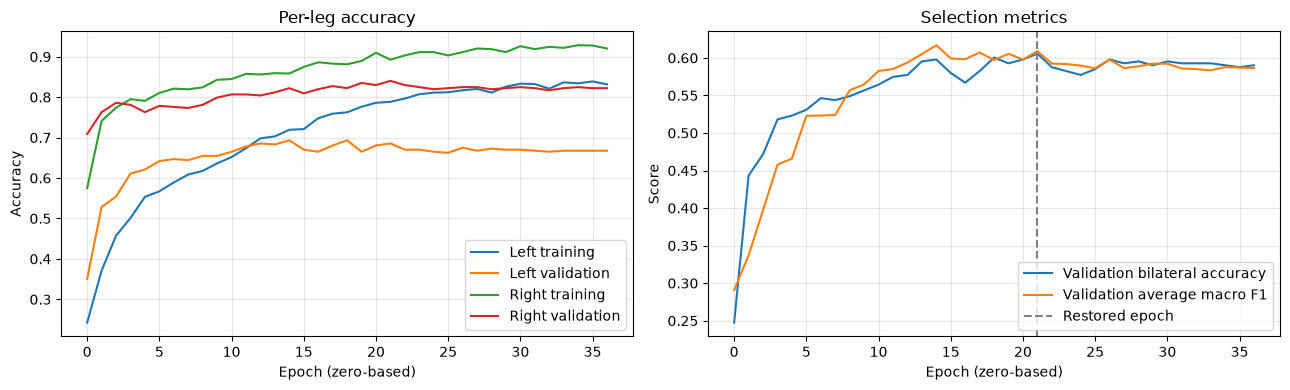

In [18]:
history = best_history
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, label in [("left_state_accuracy", "Left training"),
                    ("val_left_state_accuracy", "Left validation"),
                    ("right_state_accuracy", "Right training"),
                    ("val_right_state_accuracy", "Right validation")]:
    axes[0].plot(history.history[name], label=label)
axes[0].set(title="Per-leg accuracy", xlabel="Epoch (zero-based)", ylabel="Accuracy")
axes[1].plot(history.history["val_bilateral_accuracy"], label="Validation bilateral accuracy")
axes[1].plot(history.history["val_macro_f1"], label="Validation average macro F1")
chosen_epoch = int(np.argmax(history.history[f"val_{SELECTION_METRIC}"]))
axes[1].axvline(chosen_epoch, color="grey", linestyle="--", label="Restored epoch")
axes[1].set(title="Selection metrics", xlabel="Epoch (zero-based)", ylabel="Score")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
prob_L, prob_R = rnn_model.predict(
    X_test_seq,
    verbose=0
)

pred_L = np.argmax(prob_L, axis=1)
pred_R = np.argmax(prob_R, axis=1)

print("First 10 RNN predictions:\n")

for left, right in zip(pred_L[:10], pred_R[:10]):

    print(
        f"Left: S{left} | "
        f"Right: S{right} | "
        f"Bilateral: L{left}_R{right}"
    )

First 10 RNN predictions:

Left: S0 | Right: S1 | Bilateral: L0_R1
Left: S2 | Right: S1 | Bilateral: L2_R1
Left: S1 | Right: S1 | Bilateral: L1_R1
Left: S1 | Right: S1 | Bilateral: L1_R1
Left: S2 | Right: S1 | Bilateral: L2_R1
Left: S2 | Right: S1 | Bilateral: L2_R1
Left: S2 | Right: S1 | Bilateral: L2_R1
Left: S1 | Right: S4 | Bilateral: L1_R4
Left: S1 | Right: S4 | Bilateral: L1_R4
Left: S1 | Right: S4 | Bilateral: L1_R4


In [20]:
f1_left = f1_score(
    y_test_seq[:, 0],
    pred_L,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

f1_right = f1_score(
    y_test_seq[:, 1],
    pred_R,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

f1_average = (f1_left + f1_right) / 2

print("RNN CLASSIFIER - F1 SCORES\n")

print(f"Left-leg Macro F1:  {f1_left:.4f}")
print(f"Right-leg Macro F1: {f1_right:.4f}")
print(f"Average Macro F1:   {f1_average:.4f}")

RNN CLASSIFIER - F1 SCORES

Left-leg Macro F1:  0.5467
Right-leg Macro F1: 0.5654
Average Macro F1:   0.5561


In [21]:
accuracy_L = accuracy_score(
    y_test_seq[:, 0],
    pred_L
)

accuracy_R = accuracy_score(
    y_test_seq[:, 1],
    pred_R
)

bilateral_accuracy = np.mean(
    (pred_L == y_test_seq[:, 0])
    &
    (pred_R == y_test_seq[:, 1])
)

print("RNN CLASSIFIER - ACCURACY\n")

print(f"Left-leg Accuracy:  {accuracy_L * 100:.2f}%")
print(f"Right-leg Accuracy: {accuracy_R * 100:.2f}%")
print(f"Bilateral Accuracy: {bilateral_accuracy * 100:.2f}%")

RNN CLASSIFIER - ACCURACY

Left-leg Accuracy:  67.41%
Right-leg Accuracy: 79.10%
Bilateral Accuracy: 59.95%


In [22]:
print("Predicted left-leg states:")
print(np.unique(pred_L))

print("\nPredicted right-leg states:")
print(np.unique(pred_R))

print("\nLeft-leg prediction distribution:")
print(pd.Series(pred_L).value_counts().sort_index())

print("\nRight-leg prediction distribution:")
print(pd.Series(pred_R).value_counts().sort_index())

Predicted left-leg states:
[0 1 2 3 4]

Predicted right-leg states:
[0 1 2 3 4]

Left-leg prediction distribution:
0    202
1     22
2     62
3     29
4     87
Name: count, dtype: int64

Right-leg prediction distribution:
0    242
1     35
2     18
3     29
4     78
Name: count, dtype: int64


In [23]:
print("LEFT LEG CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test_seq[:, 0],
        pred_L,
        labels=range(N_STATES),
        target_names=[f"S{i}" for i in range(N_STATES)],
        zero_division=0
    )
)

print("\nRIGHT LEG CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test_seq[:, 1],
        pred_R,
        labels=range(N_STATES),
        target_names=[f"S{i}" for i in range(N_STATES)],
        zero_division=0
    )
)

LEFT LEG CLASSIFICATION REPORT

              precision    recall  f1-score   support

          S0       0.78      0.84      0.81       187
          S1       0.45      0.28      0.34        36
          S2       0.31      0.53      0.39        36
          S3       0.62      0.29      0.39        63
          S4       0.77      0.84      0.80        80

    accuracy                           0.67       402
   macro avg       0.59      0.55      0.55       402
weighted avg       0.68      0.67      0.66       402


RIGHT LEG CLASSIFICATION REPORT

              precision    recall  f1-score   support

          S0       0.93      0.93      0.93       243
          S1       0.49      0.55      0.52        31
          S2       0.44      0.31      0.36        26
          S3       0.21      0.26      0.23        23
          S4       0.79      0.78      0.79        79

    accuracy                           0.79       402
   macro avg       0.57      0.57      0.57       402
weighted av

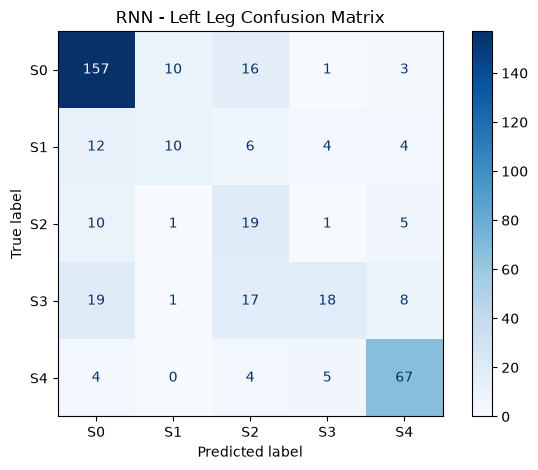

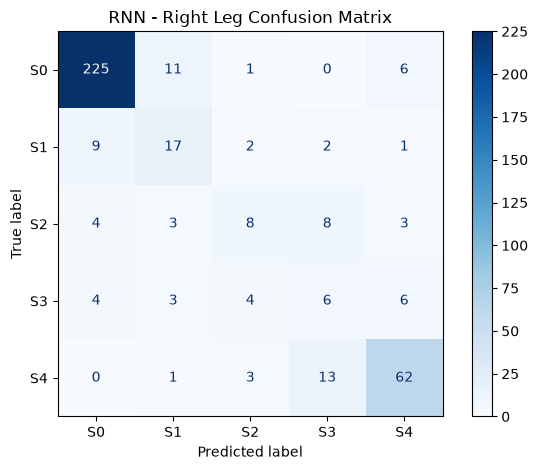

In [24]:
for side, actual, predicted in [
    ("Left", y_test_seq[:, 0], pred_L),
    ("Right", y_test_seq[:, 1], pred_R)
]:

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=range(N_STATES),
        display_labels=[f"S{i}" for i in range(N_STATES)],
        cmap="Blues"
    )

    plt.title(f"RNN - {side} Leg Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [25]:
test_results = pd.DataFrame({
    "Time_s": test_times,
    "recording_id": test_ids,

    "ActualState_L": y_test_seq[:, 0],
    "ActualState_R": y_test_seq[:, 1],

    "CandidateState_L": pred_L,
    "CandidateState_R": pred_R
})

test_results["BilateralState"] = (
    "L"
    + test_results["CandidateState_L"].astype(str)
    + "_R"
    + test_results["CandidateState_R"].astype(str)
)

print("RNN predictions:")

display(test_results.groupby("recording_id").head(5))

RNN predictions:


,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState
0,0.5994,abduction_z5,0,0,0,1,L0_R1
1,0.6994,abduction_z5,0,0,2,1,L2_R1
2,0.7994,abduction_z5,0,1,1,1,L1_R1
3,0.8993,abduction_z5,0,1,1,1,L1_R1
4,0.9993,abduction_z5,0,2,2,1,L2_R1
74,0.5994,elevating_z5,2,0,2,1,L2_R1
75,0.6994,elevating_z5,3,0,2,1,L2_R1
76,0.7994,elevating_z5,3,1,2,3,L2_R3
77,0.8993,elevating_z5,3,1,2,3,L2_R3
78,0.9993,elevating_z5,3,2,2,3,L2_R3


## Inspect the inherited transition filter

The following cells contain the original jump-rejection and motor-command
mapping. A rejected transition holds both previous states, which can also hold
a wrong prediction. The final diagnostic reports accuracy before and after
this filter, separately from model selection. Model accuracy alone does not
validate the motor-command mapping or closed-loop behavior.

In [26]:
MAX_STATE_JUMP = 3

test_results["AcceptedState_L"] = 0
test_results["AcceptedState_R"] = 0
test_results["FaultFlag"] = False

for recording_id, group in test_results.groupby(
    "recording_id",
    sort=False
):

    prev_L = None
    prev_R = None

    group = group.sort_values("Time_s")

    for index, row in group.iterrows():

        cand_L = int(row["CandidateState_L"])
        cand_R = int(row["CandidateState_R"])

        if prev_L is None:

            prev_L = cand_L
            prev_R = cand_R
            fault = False

        else:

            fault = (
                abs(cand_L - prev_L) > MAX_STATE_JUMP
                or
                abs(cand_R - prev_R) > MAX_STATE_JUMP
            )

            if not fault:
                prev_L = cand_L
                prev_R = cand_R

        test_results.loc[index, "AcceptedState_L"] = prev_L
        test_results.loc[index, "AcceptedState_R"] = prev_R
        test_results.loc[index, "FaultFlag"] = fault

print("Rejected transitions:", test_results["FaultFlag"].sum())

Rejected transitions: 36


In [27]:
def state_to_motor_command(state):
    return state / (N_STATES - 1)


test_results["MotorCommand_L"] = (
    test_results["AcceptedState_L"]
    .apply(state_to_motor_command)
)

test_results["MotorCommand_R"] = (
    test_results["AcceptedState_R"]
    .apply(state_to_motor_command)
)

display(test_results.head(10))

,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState,AcceptedState_L,AcceptedState_R,FaultFlag,MotorCommand_L,MotorCommand_R
0,0.5994,abduction_z5,0,0,0,1,L0_R1,0,1,False,0.00,0.25
1,0.6994,abduction_z5,0,0,2,1,L2_R1,2,1,False,0.50,0.25
2,0.7994,abduction_z5,0,1,1,1,L1_R1,1,1,False,0.25,0.25
3,0.8993,abduction_z5,0,1,1,1,L1_R1,1,1,False,0.25,0.25
4,0.9993,abduction_z5,0,2,2,1,L2_R1,2,1,False,0.50,0.25
5,1.0993,abduction_z5,0,3,2,1,L2_R1,2,1,False,0.50,0.25
6,1.1993,abduction_z5,0,3,2,1,L2_R1,2,1,False,0.50,0.25
7,1.2993,abduction_z5,0,4,1,4,L1_R4,1,4,False,0.25,1.00
8,1.3993,abduction_z5,0,4,1,4,L1_R4,1,4,False,0.25,1.00
9,1.4992,abduction_z5,0,4,1,4,L1_R4,1,4,False,0.25,1.00


In [28]:
# Diagnose the selected model without retuning on trial 5.
diagnostic_rows = []
for recording, group in test_results.groupby("recording_id", sort=False):
    actual_L, actual_R = group["ActualState_L"], group["ActualState_R"]
    for stage in ["Candidate", "Accepted"]:
        correct_L = group[f"{stage}State_L"] == actual_L
        correct_R = group[f"{stage}State_R"] == actual_R
        diagnostic_rows.append({
            "recording_id": recording, "stage": stage,
            "sequences": len(group),
            "left_accuracy": float(correct_L.mean()),
            "right_accuracy": float(correct_R.mean()),
            "bilateral_accuracy": float((correct_L & correct_R).mean()),
        })
recording_scores = pd.DataFrame(diagnostic_rows)
display(recording_scores)

# The inherited jump filter can change predictions. Report its effect separately.
for stage in ["Candidate", "Accepted"]:
    both_correct = (
        (test_results[f"{stage}State_L"] == test_results["ActualState_L"])
        & (test_results[f"{stage}State_R"] == test_results["ActualState_R"])
    )
    print(f"{stage} bilateral accuracy: {both_correct.mean():.2%}")

import json
rnn_model.save(RESULTS_DIR / "selected_model.keras")
joblib.dump({"imputer": imputer, "scaler": scaler,
             "feature_columns": feature_columns,
             "sequence_length": SEQUENCE_LENGTH},
            RESULTS_DIR / "preprocessing.joblib")
test_results.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
recording_scores.to_csv(RESULTS_DIR / "test_by_recording.csv", index=False)
summary = {
    "selection_metric": SELECTION_METRIC,
    "selected_configuration": best_config,
    "validation_score": float(best_score),
    "test_left_accuracy": float(accuracy_L),
    "test_right_accuracy": float(accuracy_R),
    "test_bilateral_accuracy": float(bilateral_accuracy),
    "test_average_macro_f1": float(f1_average),
    "train_trials": TRAIN_TRIALS, "validation_trials": VAL_TRIALS,
    "test_trials": TEST_TRIALS, "sequence_length": SEQUENCE_LENGTH,
    "neutral_L": float(neutral_L), "neutral_R": float(neutral_R),
    "target_definition": "original per-recording 95th-percentile tilt bins",
}
(RESULTS_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Results saved to:", RESULTS_DIR.resolve())

,recording_id,stage,sequences,left_accuracy,right_accuracy,bilateral_accuracy
0,abduction_z5,Candidate,74,0.527027,0.824324,0.459459
1,abduction_z5,Accepted,74,0.527027,0.824324,0.459459
2,elevating_z5,Candidate,91,0.472527,0.725275,0.395604
3,elevating_z5,Accepted,91,0.450549,0.725275,0.373626
4,flexing_z5,Candidate,123,0.975610,0.943089,0.926829
5,flexing_z5,Accepted,123,0.975610,0.943089,0.926829
6,sitting_z5,Candidate,53,0.792453,0.811321,0.660377
7,sitting_z5,Accepted,53,0.792453,0.811321,0.660377
8,walking_z5,Candidate,61,0.442623,0.524590,0.360656
9,walking_z5,Accepted,61,0.245902,0.163934,0.114754


Candidate bilateral accuracy: 59.95%
Accepted bilateral accuracy: 55.72%
Results saved to: /Users/sara/Desktop/Senior Project/FES-Exoskeleton-Project/Data Analysis 1 - Sara/results/rnn_lstm_accuracy_tuning
